# Plotting: every `.plot_*` method in one place

Every result object in wcc-sim and wcc-phot can draw itself. `SimulatedField` has `plot()`, `plot_cutout()`, `plot_psf_profile()` and `plot_satmask()`; `PhotometryResult` has `plot()`, `plot_field()`, `plot_centroids()` and the other panels of its diagnostic report. Each method takes `ax=None`: leave it out to get a new figure in the packaged house style, or pass an axes to draw into a figure of your own. Each returns the axes, so titles and limits can be adjusted afterwards.

The functions behind the methods live in `wcc_sim.plotting` (images, radial profiles, stamps, encircled energy), `wcc_sim.psfreport` (the PSF panels) and `wcc_phot.report` (the photometry panels). They work on plain arrays too, so an image read back from a FITS file can be shown the same way.

This notebook runs offline on a synthetic catalog: a G = 6 star that saturates and fourteen G = 18.6 to 20.5 stars around it, on a 1024 x 1024 subarray of the IMX455 in `zwo:r`. The faint stars sit just below the saturation limit: the IMX455 well holds only about 16 ke-, so at 60 s in focus anything brighter than G of about 18.5 saturates.

**Requirements:** the `py313` conda env kernel (needs `wcc_etc`).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.table import Table

import wcc_sim
import wcc_phot
from wcc_sim import simulate_field
from wcc_sim.detectors import get_geometry
from wcc_sim.wcsutil import build_wcs
from wcc_sim.plotting import use_style, TEAL, RED, AMBER

use_style()   # the packaged style, src/wcc_sim/data/plot_default.mplstyle
print(f'wcc_sim {wcc_sim.__version__} | wcc_phot {wcc_phot.__version__}')

wcc_sim 0.1.0 | wcc_phot 0.1.0


## 1. A synthetic field

The stars are laid out in pixel space and converted to sky coordinates through the same TAN WCS the simulator will build, so we know where each one lands. Row 0 of the catalog is the bright star, which is the row the PSF panels profile by default.

In [2]:
RA0, DEC0 = 150.1, 2.2
SHAPE = (1024, 1024)
EXPTIME = 60.0

geom = get_geometry('zwo:r')
w = build_wcs(RA0, DEC0, geom.plate_scale_mas, 0.0, SHAPE)
rng = np.random.default_rng(9)
n_faint = 14
x_px = np.concatenate([[512.0], rng.uniform(80, 944, n_faint)])
y_px = np.concatenate([[512.0], rng.uniform(80, 944, n_faint)])
gmag = np.concatenate([[6.0], rng.uniform(18.6, 20.5, n_faint)])
ras, decs = w.pixel_to_world_values(x_px, y_px)
cat = Table({
    'source_id': np.arange(gmag.size), 'ra': ras, 'dec': decs,
    'phot_g_mean_mag': gmag,
    'phot_bp_mean_mag': gmag + 0.4,   # BP - RP = 0.8, a G dwarf
    'phot_rp_mean_mag': gmag - 0.4,
})

field = simulate_field(RA0, DEC0, sensorfilter='zwo:r', focus=0, exptime=EXPTIME,
                       seed=1, catalog=cat, shape=SHAPE)
print(f"{field.params['n_sources']} stars, {int(field.saturation_mask.sum())} saturated px, "
      f"scatter halo {'on' if field.params['scatter'] else 'off'}")

15 stars, 3881 saturated px, scatter halo on


## 2. `field.plot()`

The delivered ADU image on an asinh stretch. `which=` switches to the electron image (`'e'`) or the noiseless expectation (`'clean'`); `catalog=True` circles the stars that land on the array and `satmask=True` outlines the saturated pixels. A full 61 Mpix frame is reduced by block maximum for display (`max_px` sets the threshold) while the axes stay in native pixels.

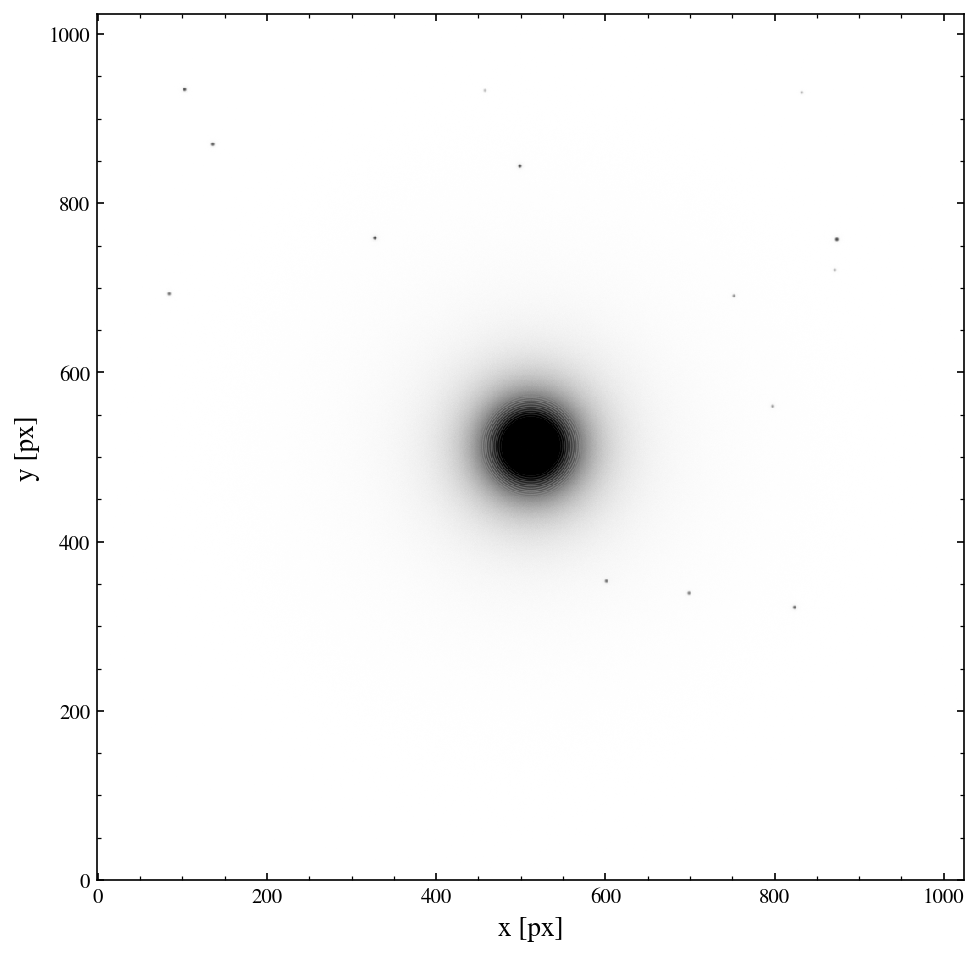

In [3]:
field.plot();

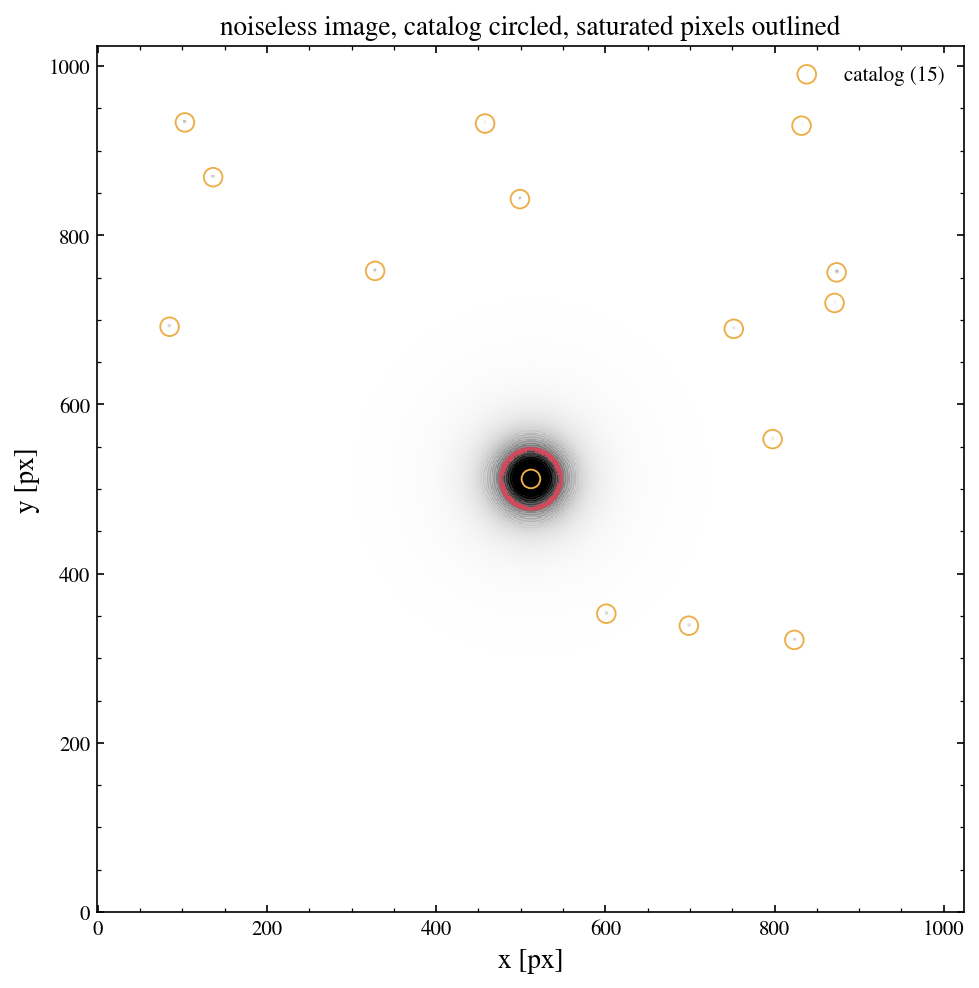

In [4]:
ax = field.plot(which='clean', catalog=True, satmask=True)
ax.set_title('noiseless image, catalog circled, saturated pixels outlined');

## 3. `field.plot_cutout()`

A cutout around one catalog row (`star=`, default 0) on a log stretch whose floor is the sky level, so the diffraction rings and the first part of the halo show. `which=` picks the image as above.

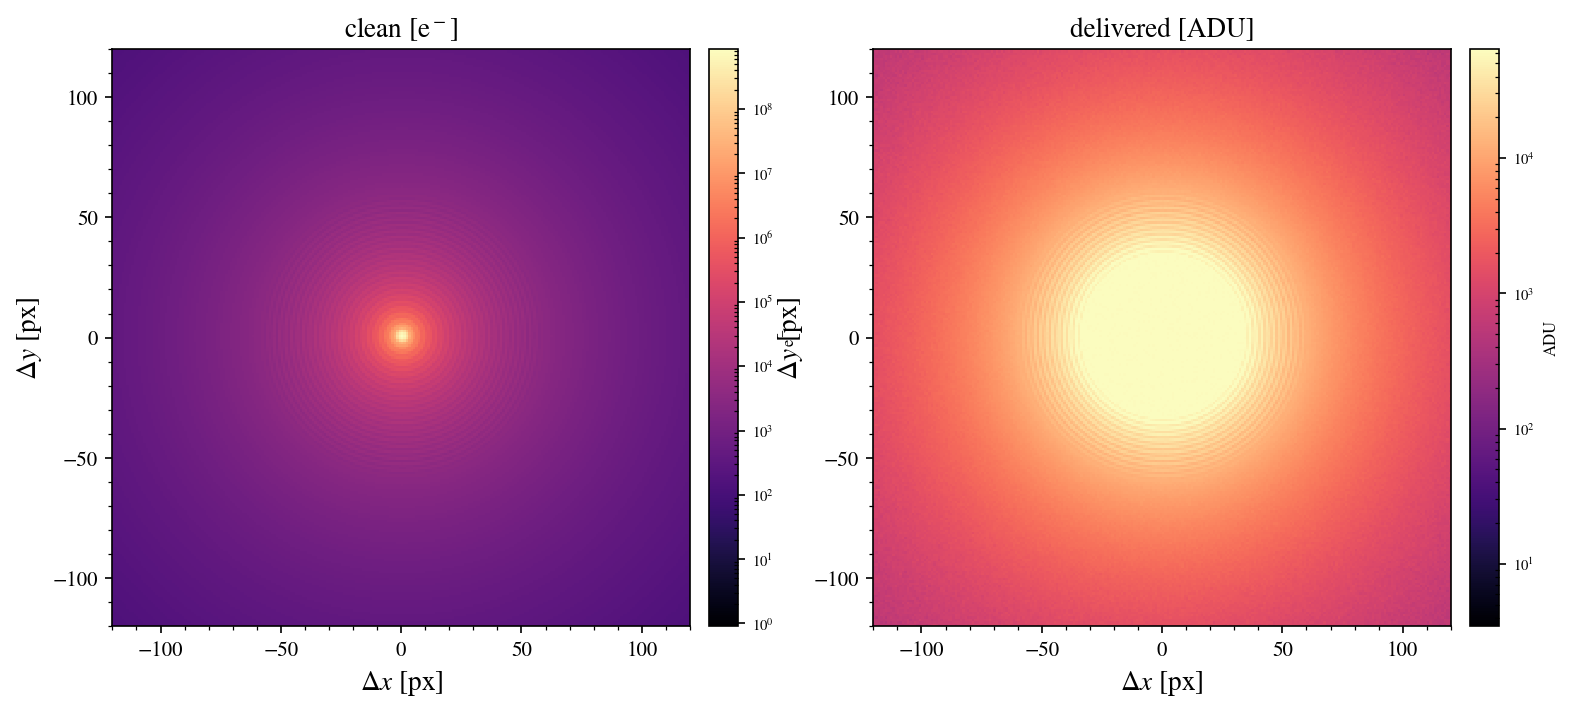

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
field.plot_cutout(ax=axes[0], half_width=120)
field.plot_cutout(ax=axes[1], half_width=120, which='adu')
axes[0].set_title('clean [e$^-$]'); axes[1].set_title('delivered [ADU]');

## 4. `field.plot_psf_profile()`

The azimuthally averaged radial profile of the bright star, split into the Airy core (with its fitted wing), the scattered-light halo, and their total, against what actually landed in the noiseless image. The vertical lines mark the stamp edge, the crossover where the halo overtakes the diffraction wing, and the radius to which the star was drawn. The same panel is the centrepiece of the PSF report.

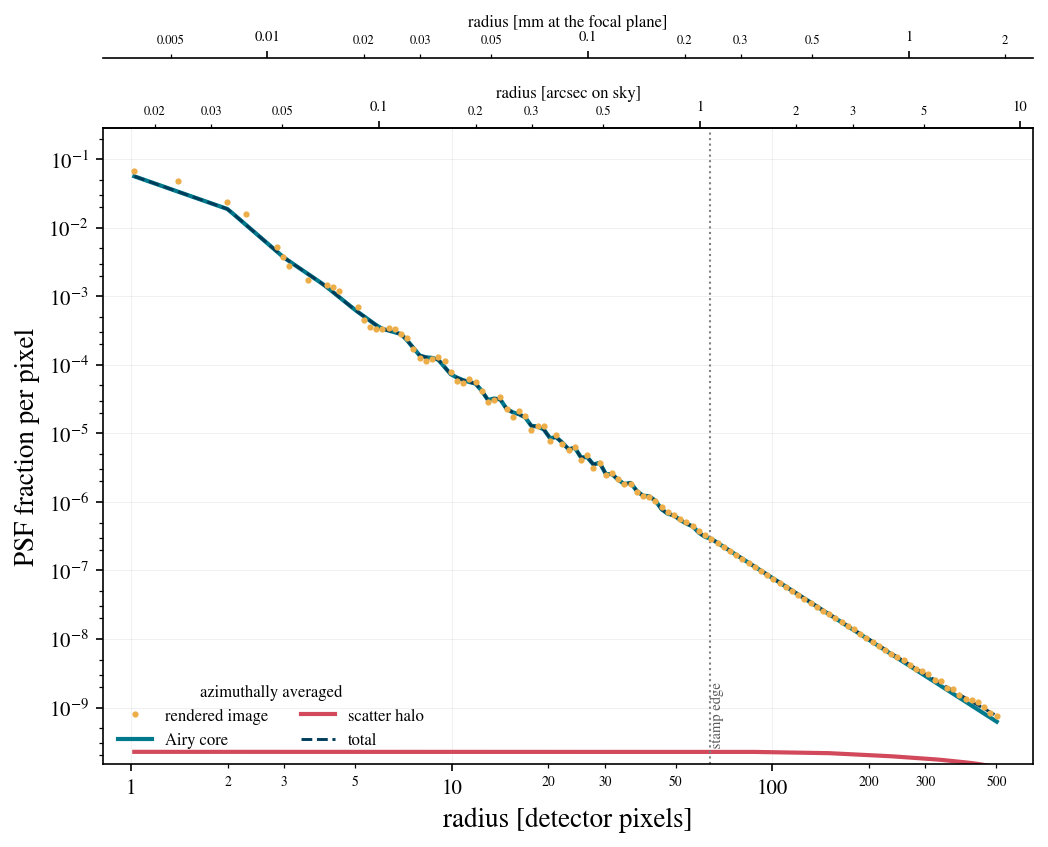

In [6]:
field.plot_psf_profile();

## 5. `field.plot_satmask()` and `field.psf_report()`

The saturation mask on its own, and the full one-page PSF report. `psf_report(path)` writes a PDF and a PNG and returns both paths; `build_psf_figure()` returns the figure itself, which is handy inside a notebook.

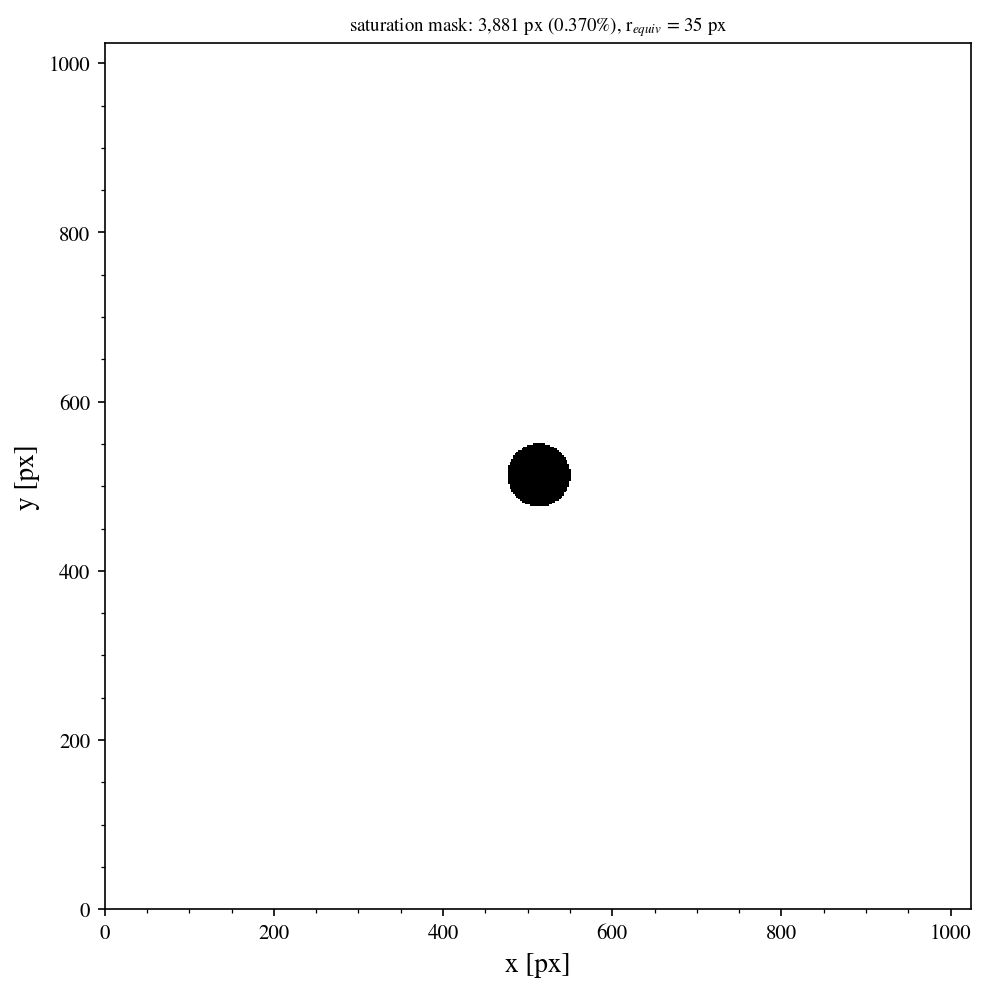

In [7]:
field.plot_satmask();

wrote psf_report.pdf and psf_report.png
Airy peak / scatter peak = 5.77e+08, crossover at 1196 px, drawn to 1811 px


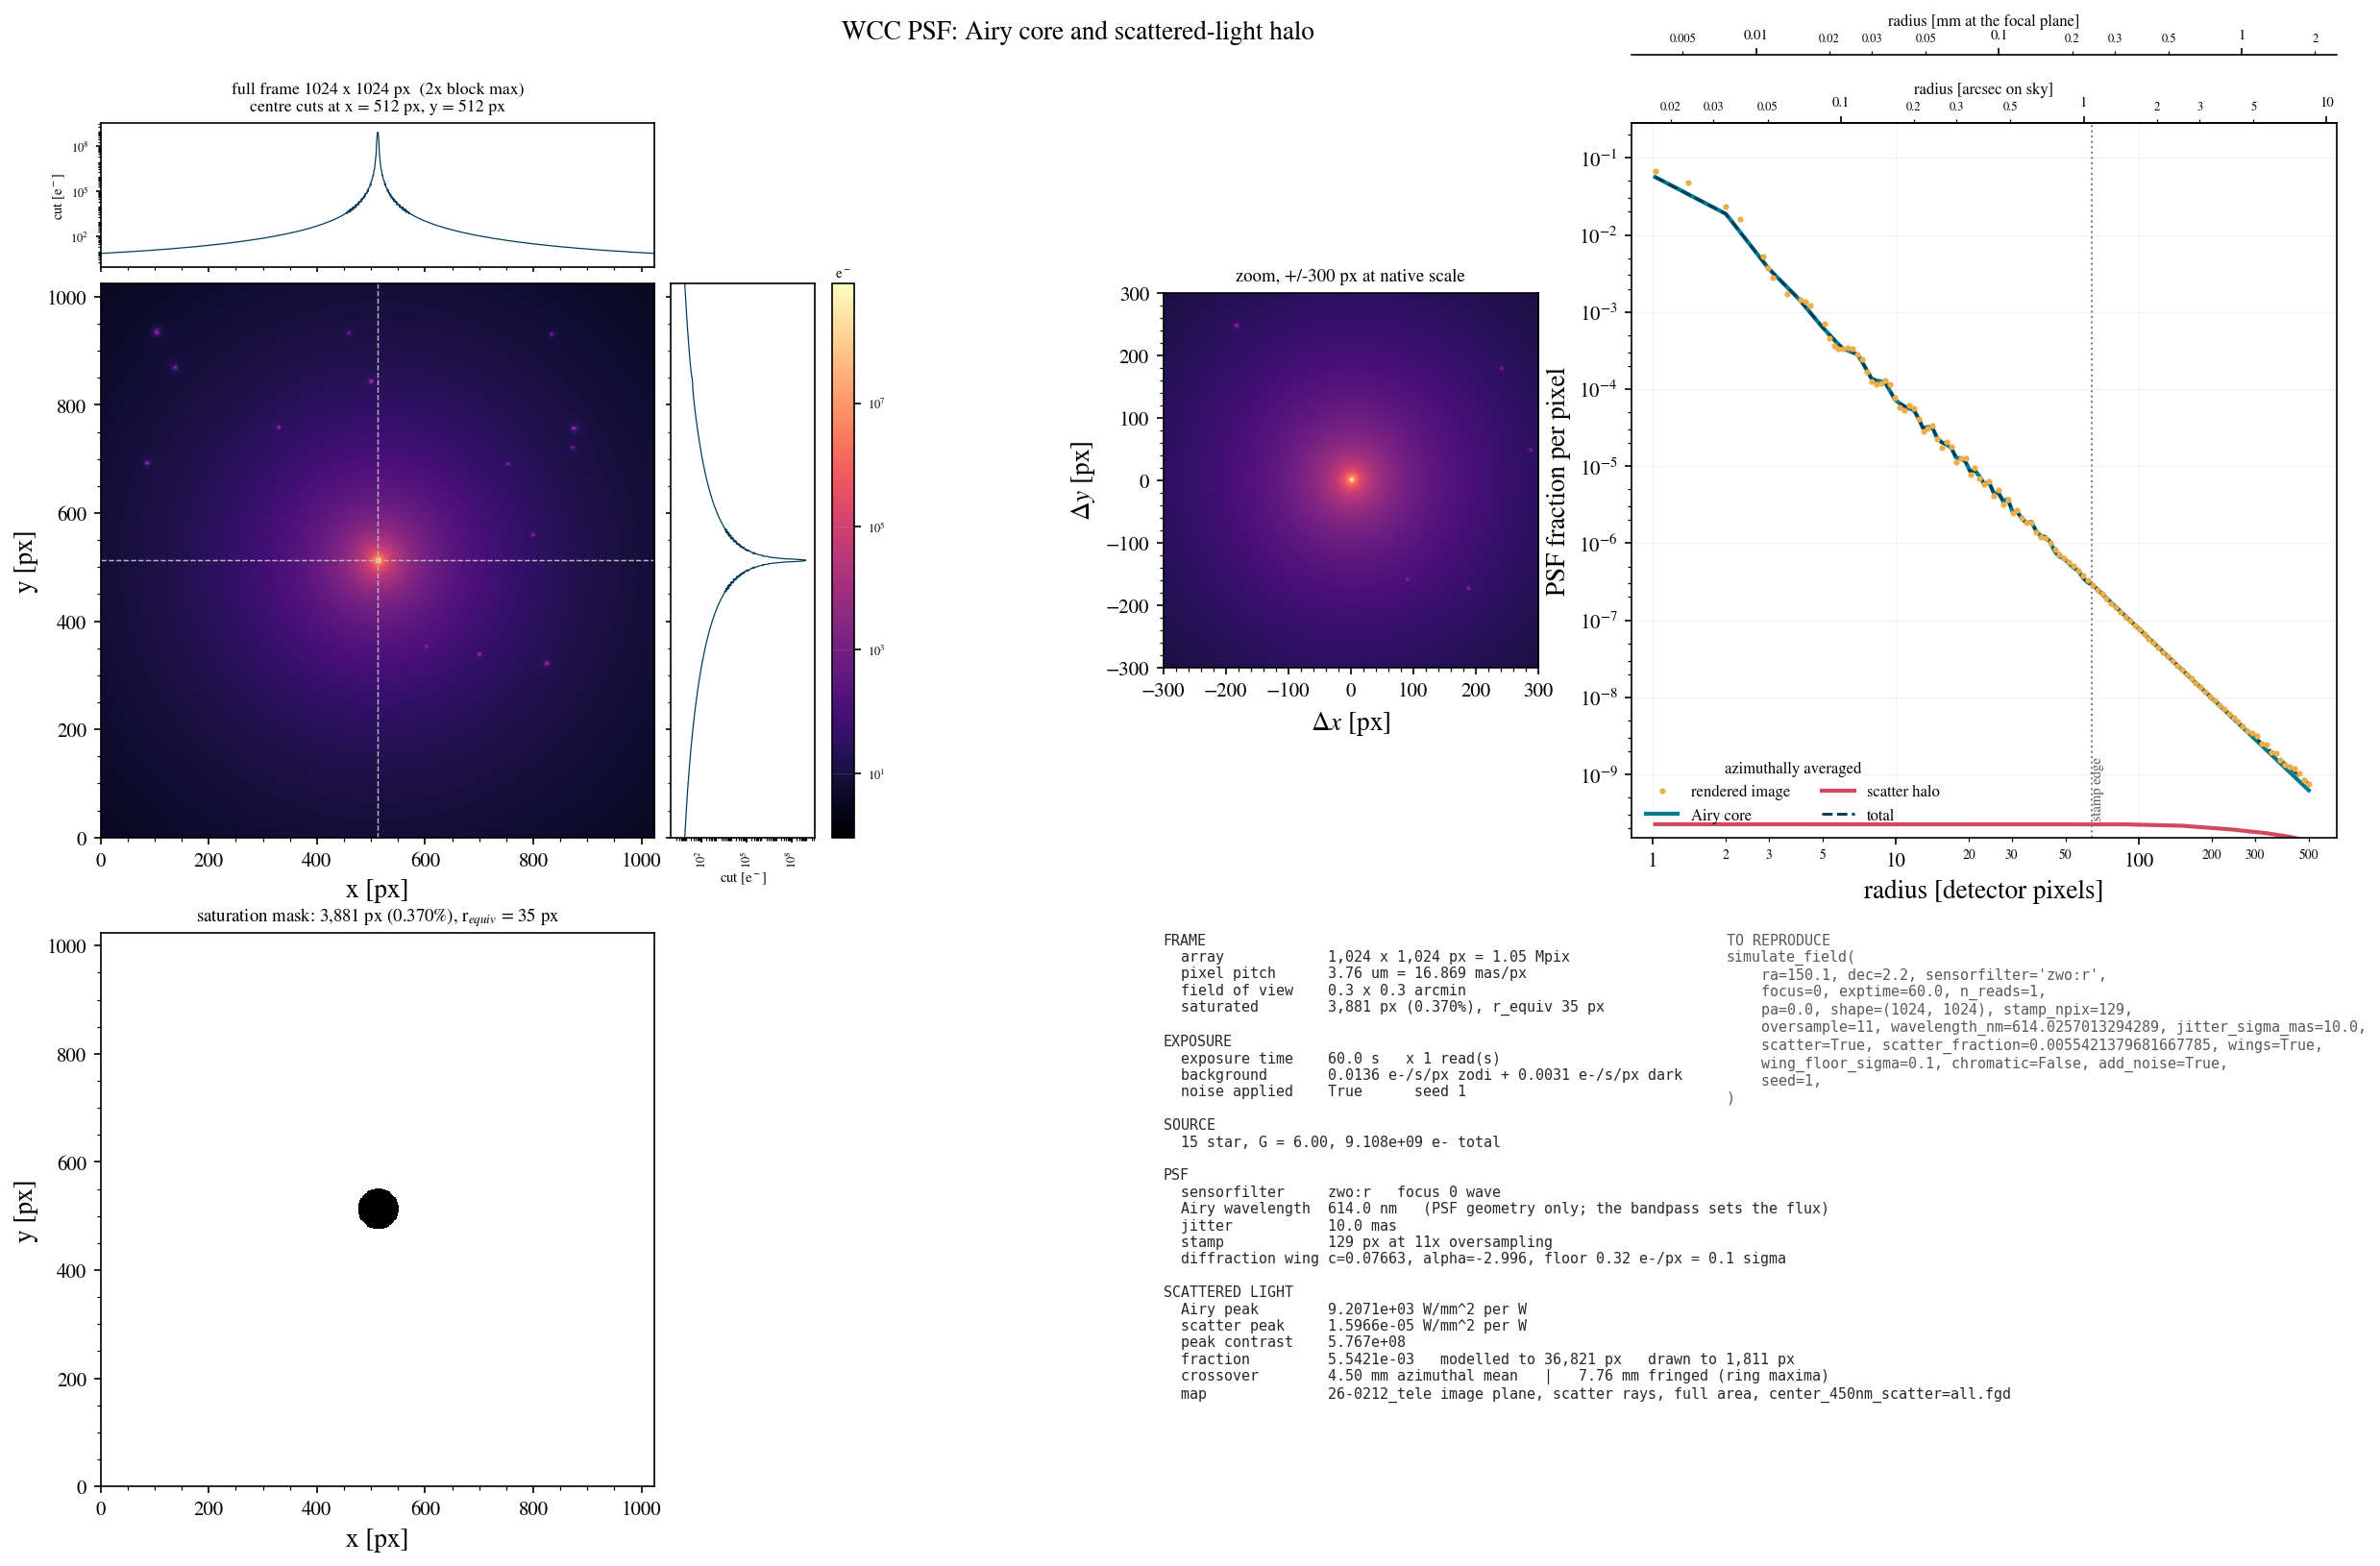

In [8]:
import tempfile, os
from wcc_sim.psfreport import build_psf_figure, psf_decomposition

outdir = tempfile.mkdtemp()
pdf, png = field.psf_report(os.path.join(outdir, 'psf_report.pdf'))
print('wrote', os.path.basename(pdf), 'and', os.path.basename(png))

dec = psf_decomposition(field)
print(f"Airy peak / scatter peak = {dec['contrast']:.2e}, "
      f"crossover at {dec['crossover_px']:.0f} px, drawn to {dec['r_out_px']:.0f} px")

fig, _ = build_psf_figure(field)
fig

## 6. Stamps, radial profiles and encircled energy

The functions in `wcc_sim.plotting` take arrays. `field.models['stamp']` is the detector-sampled PSF stamp the render used; `plot_stamp()` shows it on a log colour scale (in arcsec when given a plate scale), `plot_encircled_energy()` the cumulative fraction inside each radius, and `plot_radial_profile()` the mean in annuli about any point of any image.

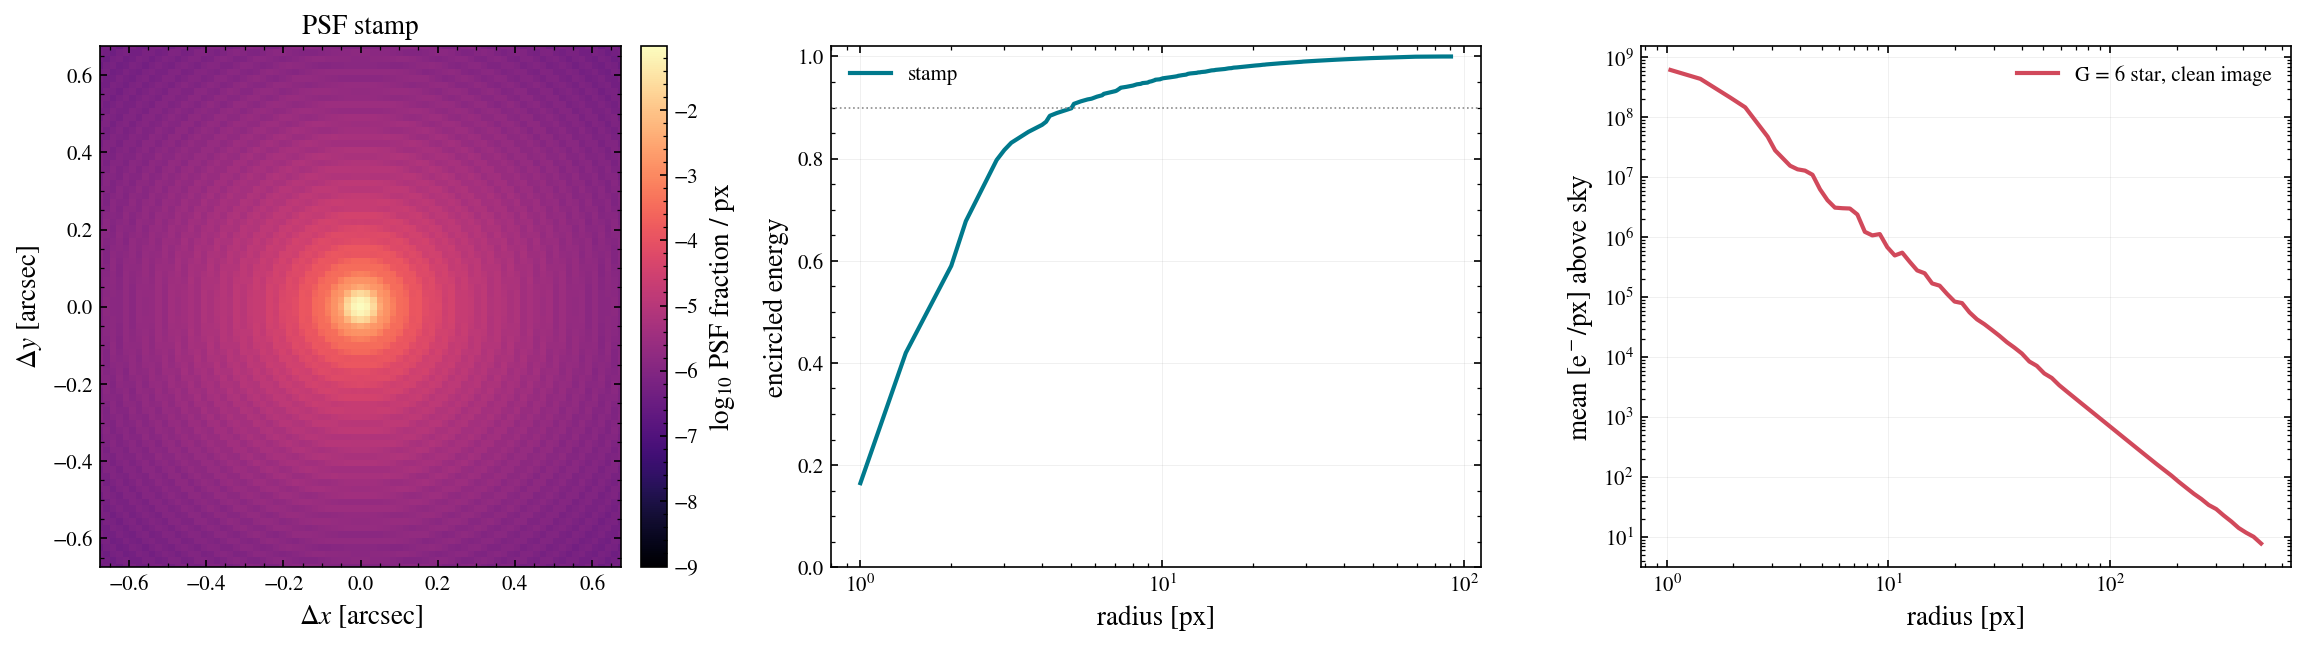

In [9]:
from wcc_sim.plotting import plot_stamp, plot_encircled_energy, plot_radial_profile

stamp = field.models['stamp']
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
plot_stamp(stamp, ax=axes[0], half_width=40, plate_scale_mas=field.params['plate_scale_mas'],
           title='PSF stamp')
plot_encircled_energy(stamp, ax=axes[1], color=TEAL, label='stamp')
axes[1].axhline(0.9, color='0.55', ls=':', lw=0.8)
bg = (field.params['sky_e_s'] + field.params['dark_e_s']) * EXPTIME
plot_radial_profile(field.image_clean, 512, 512, ax=axes[2], bg=bg, r_max=500, log=True,
                    color=RED, label='G = 6 star, clean image')
axes[2].set_ylabel('mean [e$^-$/px] above sky')
plt.tight_layout()

## 7. Photometry: `PhotometryResult.plot_*`

Five dithered frames of the same field, then differential photometry of one of the faint stars against the others. `result.plot()` is the light curve; `plot_field(frame)` shows the apertures; the remaining methods are the panels of the diagnostic report, drawn here into one grid through `ax=`.

In [10]:
from wcc_phot import run_photometry

PIX_DEG = geom.plate_scale_mas / 1000.0 / 3600.0
frames = [field] + [
    simulate_field(RA0 + dx * PIX_DEG, DEC0 + dy * PIX_DEG, sensorfilter='zwo:r', focus=0,
                   exptime=EXPTIME, seed=2 + k, catalog=cat, shape=SHAPE)
    for k, (dx, dy) in enumerate([(0.4, -0.2), (-0.3, 0.3), (0.1, 0.5), (-0.5, -0.1)])
]
faint = field.catalog[~np.asarray(field.catalog['saturated'], dtype=bool)]
target_id = int(faint['source_id'][np.argmin(np.abs(faint['phot_g_mean_mag'] - 19.0))])
res = run_photometry(frames, target=target_id, method='aperture', n_ref=5)
print(f"target {target_id} (G = {res.stars['gmag'][0]:.2f}), {res.params['n_ref']} references, "
      f"r_ap = {res.params['r_ap']:.0f} px")

target 7 (G = 18.97), 5 references, r_ap = 9 px


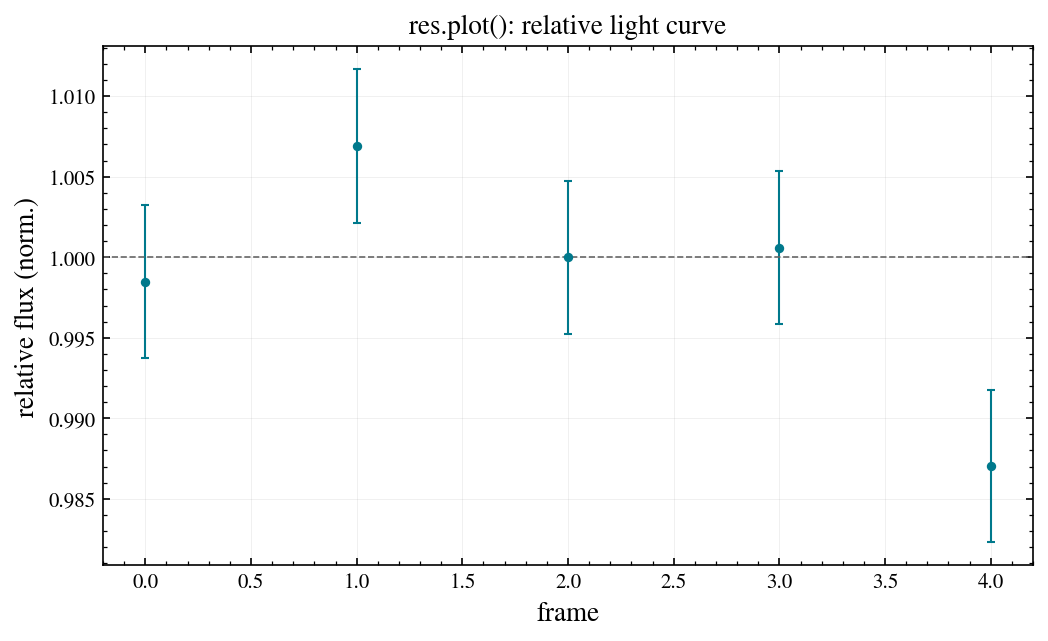

In [11]:
ax = res.plot()
ax.set_title('res.plot(): relative light curve');

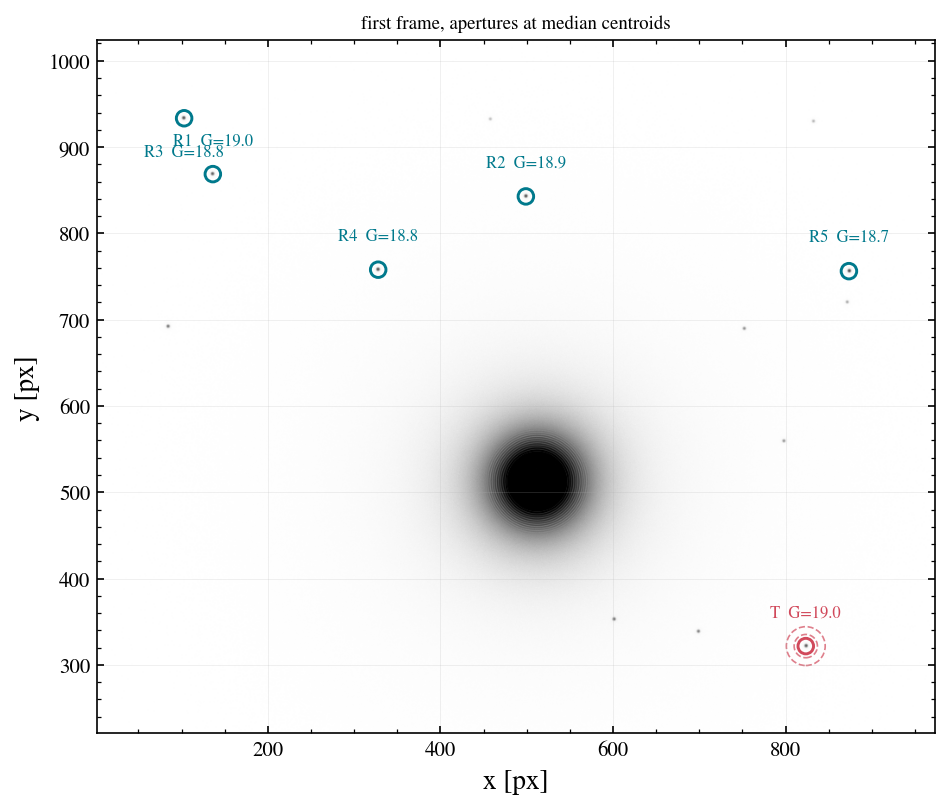

In [12]:
res.plot_field(frames[0]);

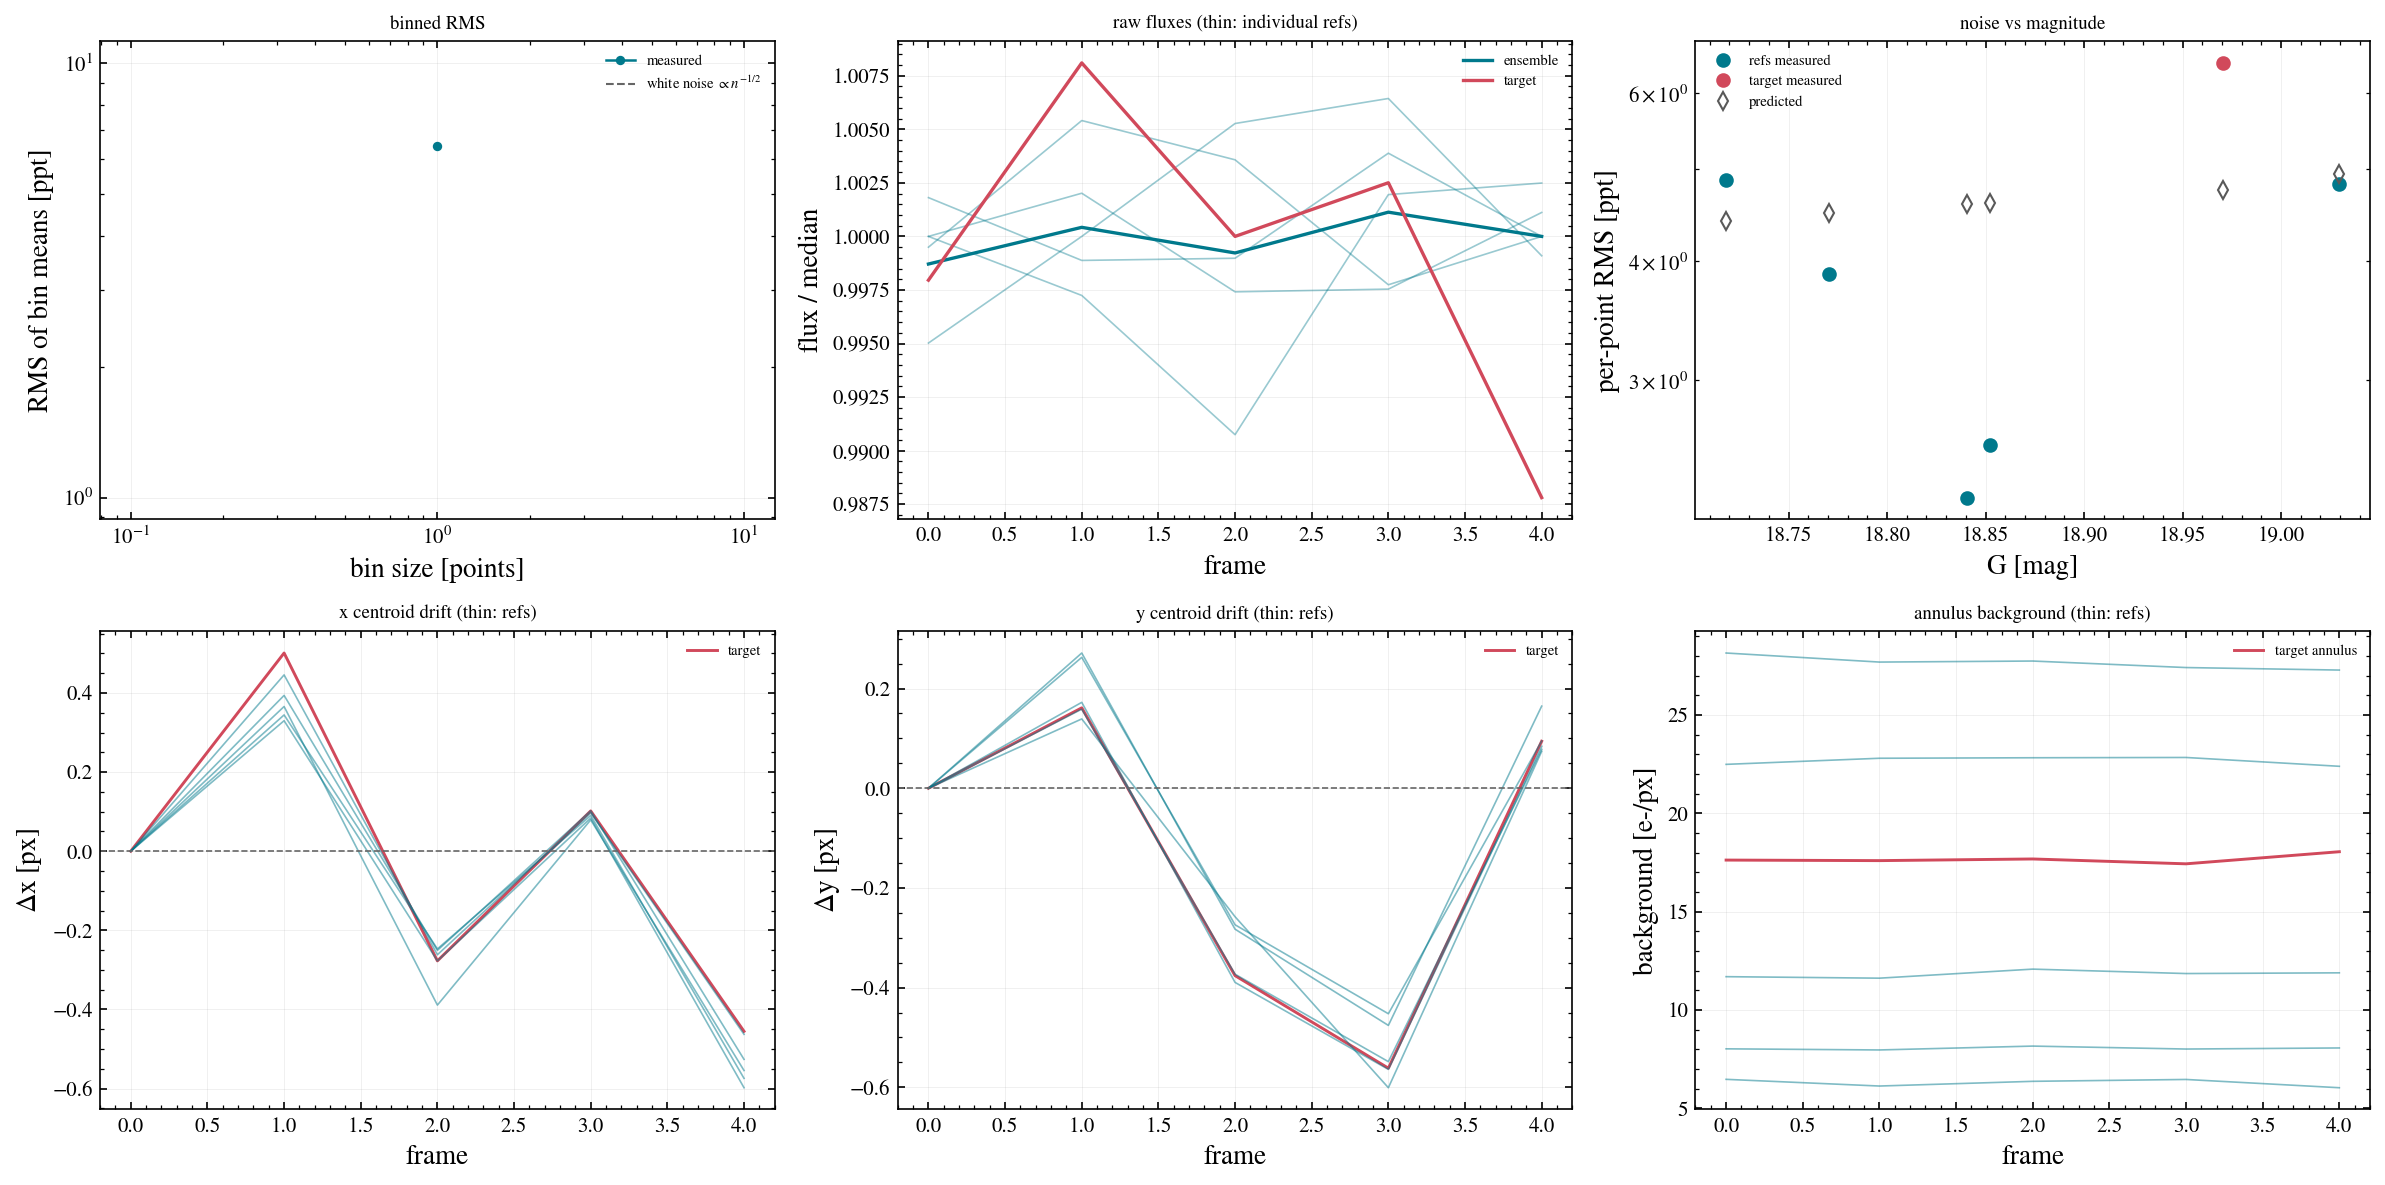

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
res.plot_binned_rms(ax=axes[0, 0])
res.plot_raw_fluxes(ax=axes[0, 1])
res.plot_rms_vs_mag(ax=axes[0, 2])
res.plot_centroids(ax=axes[1, 0], coord='x')
res.plot_centroids(ax=axes[1, 1], coord='y')
res.plot_background(ax=axes[1, 2])
plt.tight_layout()

`res.report(path, frame=...)` writes the same panels, plus a summary block, as a one-page PDF and PNG (the `--report` flag of `wcc-phot` does the same from the shell).

wrote ['phot_report.pdf', 'phot_report.png']


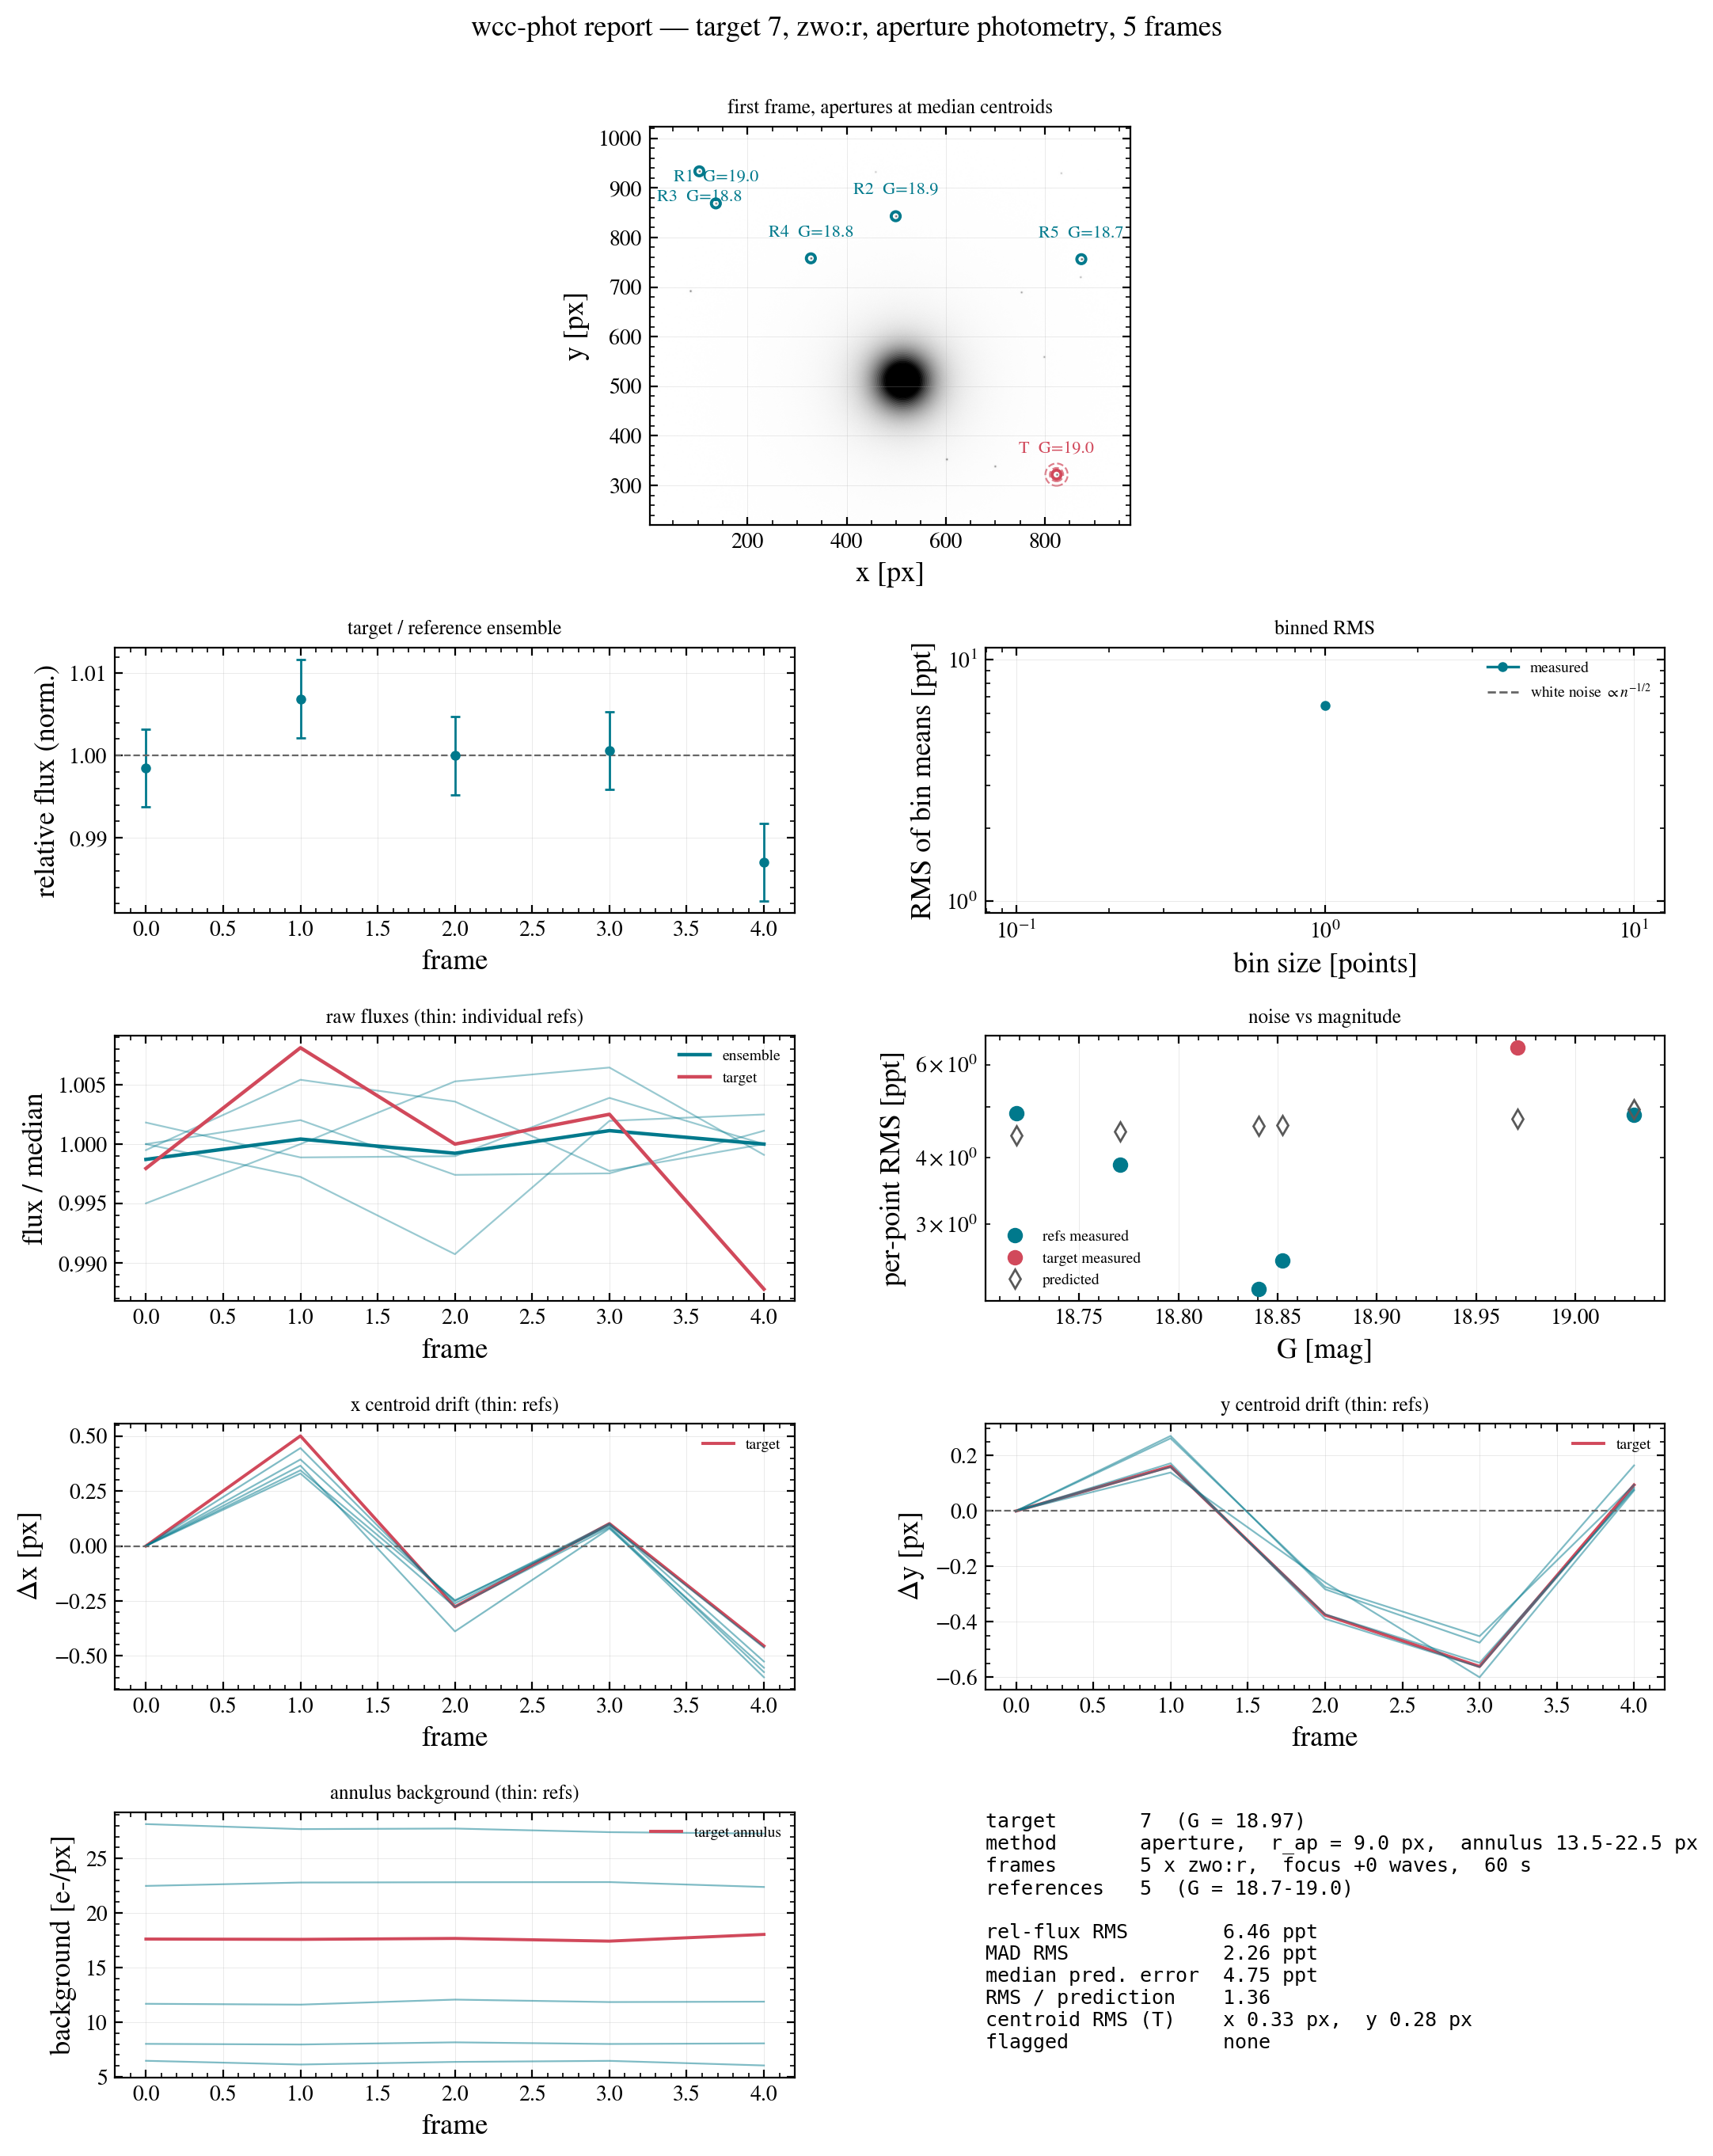

In [14]:
paths = res.report(os.path.join(outdir, 'phot_report.pdf'), frame=frames[0])
print('wrote', [os.path.basename(p) for p in paths])

from IPython.display import Image
Image(paths[1], width=700)

## Summary

| Object | Method | Shows |
|---|---|---|
| `SimulatedField` | `plot(which, catalog, satmask)` | the image with an asinh stretch |
| | `plot_cutout(star, half_width, which)` | a log-stretched cutout around one star |
| | `plot_psf_profile(star)` | Airy core, scatter halo, total, and the rendered profile |
| | `plot_satmask()` | the saturation mask |
| | `psf_report(path)` | the one-page PSF report (PDF + PNG) |
| `PhotometryResult` | `plot()` / `plot_lightcurve()` | the relative light curve |
| | `plot_field(frame)` | the frame with apertures at the median centroids |
| | `plot_binned_rms()`, `plot_raw_fluxes()`, `plot_rms_vs_mag()` | noise diagnostics |
| | `plot_centroids(coord)`, `plot_background()` | per-frame drift and annulus background |
| | `report(path, frame)` | the one-page photometry report (PDF + PNG) |
| `wcc_sim.plotting` | `plot_image`, `plot_stamp`, `plot_radial_profile`, `plot_encircled_energy` | the same plots for plain arrays |

All of them take `ax=None` and return the axes. `use_style()` applies the packaged style to a whole session; without it, only the figures the methods create themselves are styled.